# Solutions to the exercises of Chapter 1

**Chapter:** [1. Pair potentials, reduced units, and periodic boundary conditions](../../notebooks/part1_nve_md/01_potentials_and_pbc.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
pos_fcc, L_fcc = es.make_fcc_lattice(n_cells=3, rho=0.8442)  # N = 108 particles
forces, u_tot, virial = es.lj_forces_all_pairs(pos_fcc, L_fcc, rc=2.5, shifted=True)
print(f"FCC crystal (N={len(pos_fcc)}, L={L_fcc:.3f}): U/N = {u_tot/len(pos_fcc):.5f}, Argon tau = {es.ARGON.t_to_ps(1.0):.3f} ps")

FCC crystal (N=108, L=5.039): U/N = -6.33281, Argon tau = 2.156 ps


Force gradient check: analytical = -5.72856456, FD = -5.72856453, rel_err = 4.28e-09


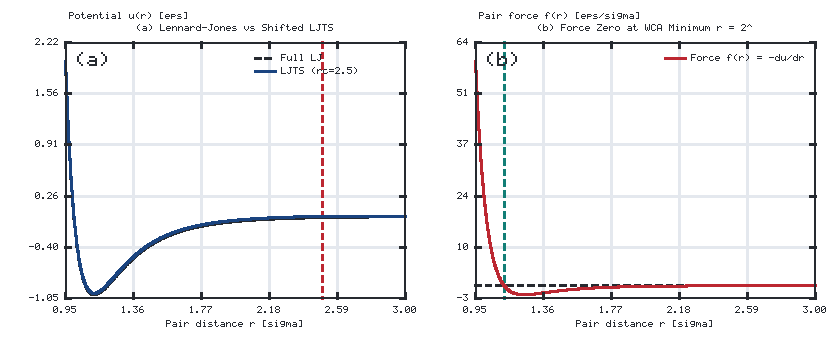

In [3]:
# 1. Verify Newton's Third Law: sum_i f_i == 0
net_force = float(np.linalg.norm(np.sum(forces, axis=0)))
assert net_force < 1e-12

# 2. Verify analytical force against central finite-difference -dU/dx on a perturbed atom
pos_p = pos_fcc.copy(); pos_p[0, 0] += 0.08
f_p, _, _ = es.lj_forces_all_pairs(pos_p, L_fcc, rc=2.5, shifted=True)
eps = 1e-6
p_plus = pos_p.copy(); p_plus[0, 0] += eps
p_minus = pos_p.copy(); p_minus[0, 0] -= eps
_, u_plus, _ = es.lj_forces_all_pairs(p_plus, L_fcc, rc=2.5, shifted=True)
_, u_minus, _ = es.lj_forces_all_pairs(p_minus, L_fcc, rc=2.5, shifted=True)
f_fd = -(u_plus - u_minus) / (2.0 * eps)
rel_err = abs(f_p[0, 0] - f_fd) / abs(f_fd)
print(f"Force gradient check: analytical = {f_p[0,0]:.8f}, FD = {f_fd:.8f}, rel_err = {rel_err:.2e}")
assert rel_err < 1e-7

# 3. Diagnostic Figure: LJ vs LJTS potential and force curves
r_g = np.linspace(0.95, 3.0, 120)
u_lj = 4.0 * (r_g**-12 - r_g**-6)
u_rc = 4.0 * (2.5**-12 - 2.5**-6)
u_ljts = np.where(r_g < 2.5, u_lj - u_rc, 0.0)
f_ljts = np.where(r_g < 2.5, 24.0 * (2.0 * r_g**-13 - r_g**-7), 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(r_g, u_lj, "k--", label="Full LJ")
ax1.plot(r_g, u_ljts, "b-", label="LJTS (rc=2.5)")
ax1.axvline(2.5, color="r")
ax1.set_xlabel("Pair distance r [sigma]"); ax1.set_ylabel("Potential u(r) [eps]")
ax1.set_title("(a) Lennard-Jones vs Shifted LJTS"); panel_label(ax1, "(a)")

ax2.plot(r_g, f_ljts, "r-", label="Force f(r) = -du/dr")
ax2.axhline(0.0, color="k")
ax2.axvline(2.0**(1.0/6.0), color="g")
ax2.set_xlabel("Pair distance r [sigma]"); ax2.set_ylabel("Pair force f(r) [eps/sigma]")
ax2.set_title("(b) Force Zero at WCA Minimum r = 2^(1/6)"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 1
u_t25, _ = es.lj_tail_corrections(0.8, 2.5)
u_t50, _ = es.lj_tail_corrections(0.8, 5.0)
assert np.isclose(u_t25 / u_t50, 8.0, rtol=0.05)

rhos = np.linspace(0.85, 1.15, 16)
u_fcc_scan = [es.lj_forces_all_pairs(*es.make_fcc_lattice(3, float(rh)), rc=2.5, shifted=True)[1] / 108.0 for rh in rhos]
rho_eq = float(rhos[int(np.argmin(u_fcc_scan))])
print(f"Ch 1 Exercises — Equilibrium T=0 FCC density rho_0* = {rho_eq:.3f}, U_min/N = {min(u_fcc_scan):.4f}")
assert 0.95 <= rho_eq <= 1.12

pos_shifted = es.wrap_positions(pos_fcc + np.array([1.7, -2.3, 0.9]), L_fcc)
_, u_shift_chk, _ = es.lj_forces_all_pairs(pos_shifted, L_fcc, rc=2.5, shifted=True)
assert np.isclose(u_shift_chk, u_tot, rtol=1e-12)

Ch 1 Exercises — Equilibrium T=0 FCC density rho_0* = 1.070, U_min/N = -7.4511
